# False RGB, geographic panels, and an interactive map
The false RGB recipe matches this package: I03 → red, I02 → green,
I01 → blue, fixed 0–0.6 display stretch and gamma 2.2. Radiance units remain
unverified; this is a display transform, not a reflectance calculation.
All four panels use the actual two-dimensional longitude/latitude grids,
including the false RGB, preserving the curved native footprint.


In [1]:
from pathlib import Path
import os, sys
REPO = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0, str(REPO / 'examples'))
from flare_sample import data_root, scenes, open_scene, false_rgb, nearest_pixel, interactive_map
DATA = data_root(os.environ.get('FLARE_DATA_DIR', str(REPO / 'data')))
FORMAT = 'netcdf'  # Public sample is included; use 'zarr' for an approved full download.
TAGS = scenes(DATA, FORMAT)
OUTPUT = REPO / 'outputs'
OUTPUT.mkdir(exist_ok=True)
print(f'{len(TAGS)} scenes; {TAGS[0]} through {TAGS[-1]}. All times UTC.')


6 scenes; 20260716T1801 through 20260716T1826. All times UTC.


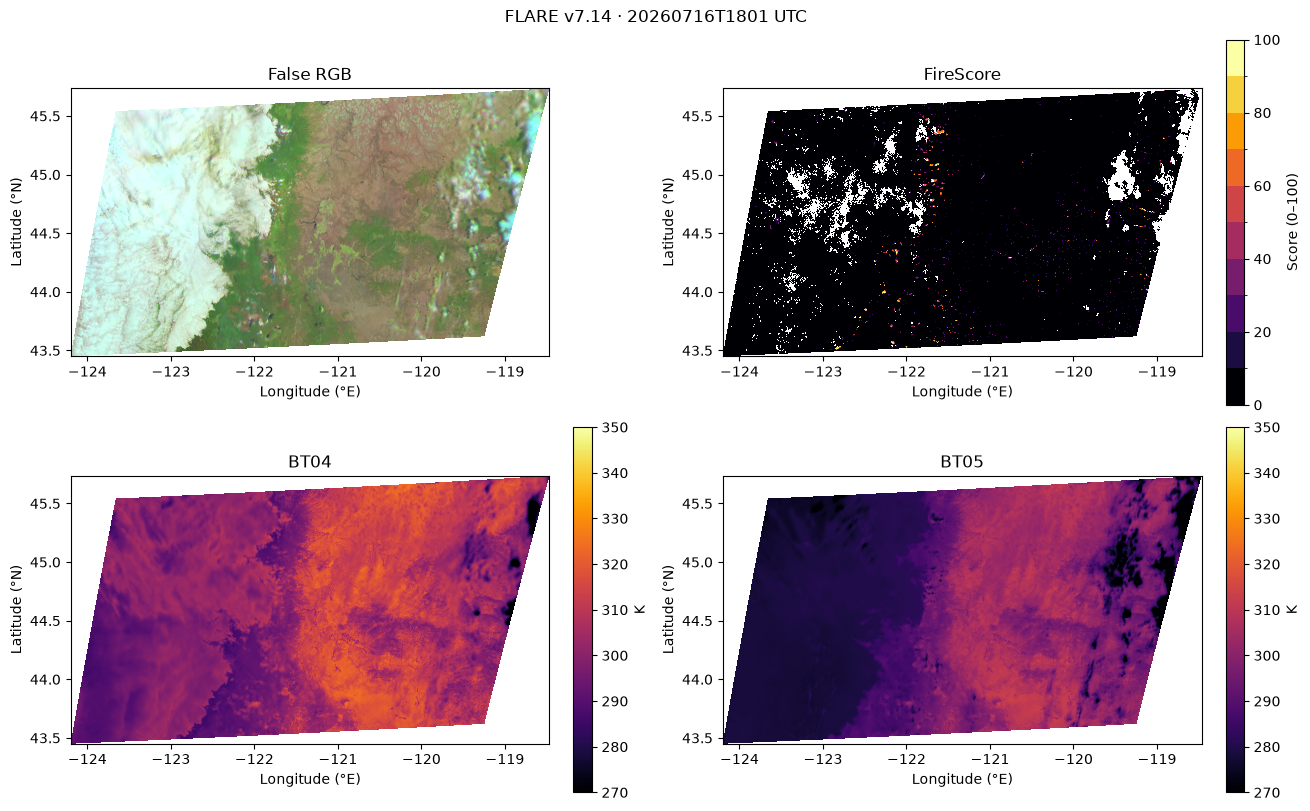

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
TAG = TAGS[0]  # Change this to any entry in TAGS.
def plot_scene(tag):
    with open_scene(DATA,tag,FORMAT) as ds:
        fig, axes = plt.subplots(2,2,figsize=(13,8),constrained_layout=True)
        axes[0,0].pcolormesh(ds.lon, ds.lat, false_rgb(ds) / 255.0,
                               shading='nearest', rasterized=True)
        axes[0,0].set(title='False RGB', xlabel='Longitude (°E)', ylabel='Latitude (°N)')
        axes[0,0].set_aspect(1/np.cos(np.deg2rad(float(ds.lat.mean()))))
        for ax,key in zip([axes[0,1],axes[1,0],axes[1,1]],['FireScore','BT04','BT05']):
            opts = dict(cmap=plt.get_cmap('inferno',10),norm=BoundaryNorm(np.arange(0,101,10),10,clip=True)) if key=='FireScore' else dict(cmap='inferno',vmin=270,vmax=350)
            im=ax.pcolormesh(ds.lon,ds.lat,ds[key],shading='nearest',rasterized=True,**opts)
            ax.set(title=key,xlabel='Longitude (°E)',ylabel='Latitude (°N)')
            ax.set_aspect(1/np.cos(np.deg2rad(float(ds.lat.mean()))))
            fig.colorbar(im,ax=ax,label='Score (0–100)' if key=='FireScore' else 'K')
        fig.suptitle(f'FLARE v7.14 · {tag} UTC')
        fig.savefig(OUTPUT/f'{tag}_panels.png',dpi=160)
        plt.show()
plot_scene(TAG)


## Choose a timestamp interactively
The dropdown reruns the plot and saves the selected frame. Widgets require a
running Jupyter kernel; static previews on GitHub do not execute Python.


In [3]:
import ipywidgets as widgets
from IPython.display import display
picker=widgets.Dropdown(options=TAGS,value=TAG,description='UTC scene:')
button=widgets.Button(description='Plot selected scene')
result=widgets.Output()
def redraw(_):
    with result:
        result.clear_output(wait=True)
        plot_scene(picker.value)
button.on_click(redraw)
display(widgets.VBox([picker,button,result]))


## Zoomable map
RGB and score overlays are explicitly reprojected from the curved native grid
to Web Mercator with nearest-neighbor sampling. Toggle layers, change opacity
in the helper if desired, and click to read coordinates. Basemap tiles and
Leaflet assets require internet. The HTML export can be opened separately.



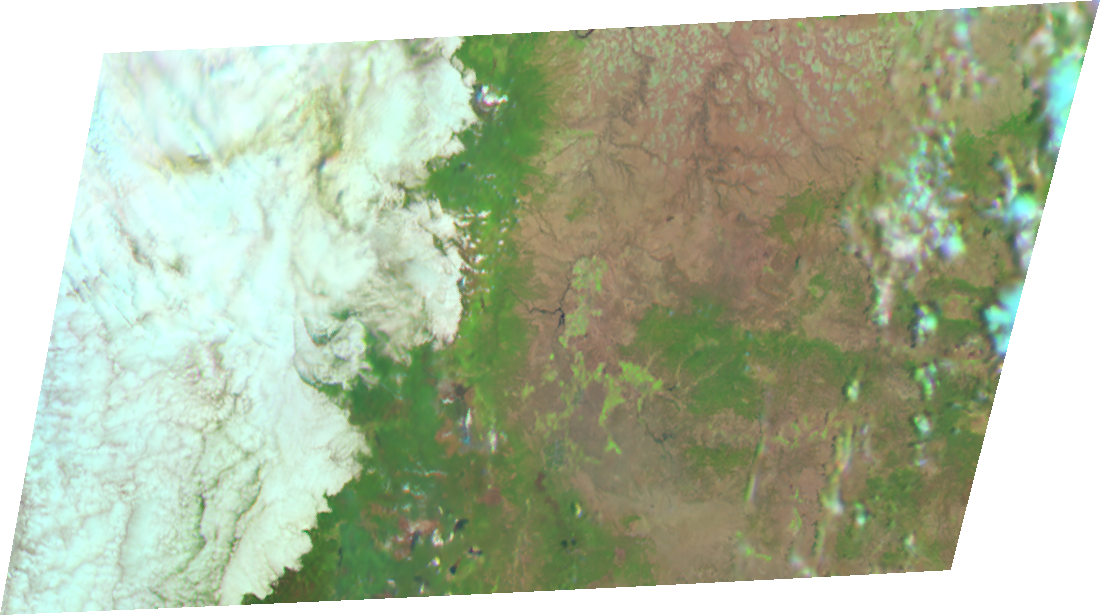
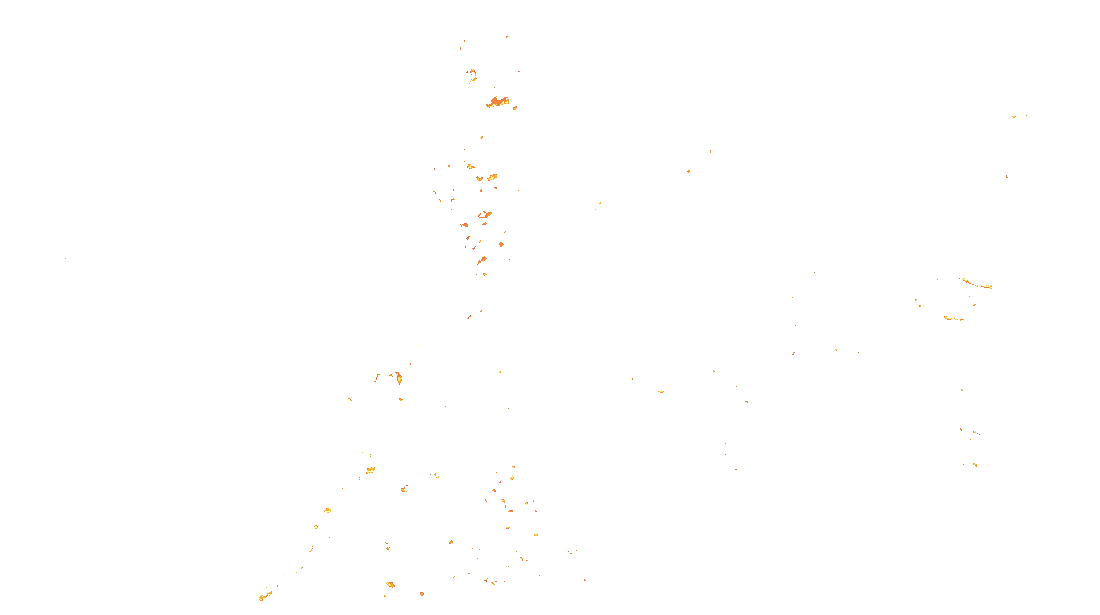

In [4]:
with open_scene(DATA,TAG,FORMAT) as ds:
    m=interactive_map(ds,threshold=60)
m.save(str(OUTPUT/f'{TAG}_map.html'))
display(m)
